# Table of Contents
- 1. Correlation Matrix Heatmaps (Pearson, Spearman, Cramér's V)
- 2. Variance Inflation Factor (VIF) for Collinearity
- 3. Partial Correlation Analysis
- 4. Non-Linear Association Detection (Maximal Information Coefficient)

In [11]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for correlation and collinearity discovery loaded successfully.")

Global libraries for correlation and collinearity discovery loaded successfully.


1. Correlation Matrix Heatmaps (Pearson, Spearman, Cramér's V)
$$r_{xy} = \frac{\sum_{i=1}^N (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^N (x_i - \bar{x})^2 \sum_{i=1}^N (y_i - \bar{y})^2}}$$


   feature_1  feature_2  feature_3
0   0.374540   0.062858   0.231630
1   0.950714   1.272821   0.783797
2   0.731994   0.628712   0.614902
____________________________________________________________
Correlation Matrix:
            feature_1  feature_2  feature_3
feature_1   1.000000  -0.034033   0.915235
feature_2  -0.034033   1.000000   0.053721
feature_3   0.915235   0.053721   1.000000


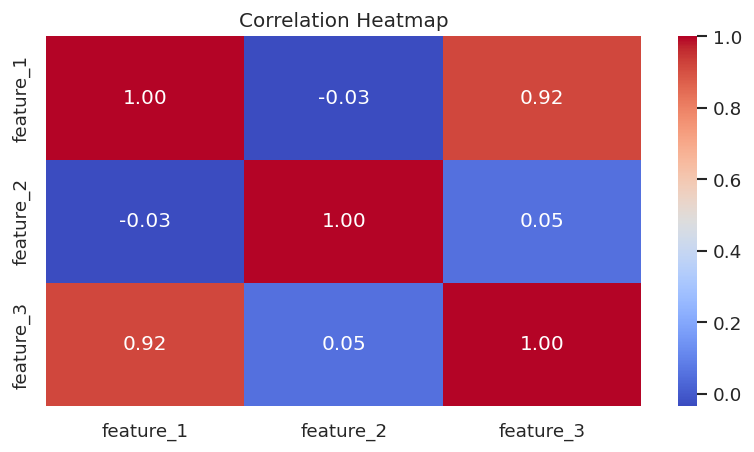

In [12]:
np.random.seed(42)
df_corr = pd.DataFrame({
    'feature_1': np.random.rand(100),
    'feature_2': np.random.rand(100) * 2
})
df_corr['feature_3'] = df_corr['feature_1'] * 0.8 + np.random.normal(0, 0.1, 100)
print(df_corr.head(3))
print("_" * 60)
corr_matrix = df_corr.corr(method='pearson') # method : 'pearson', 'kendall', 'spearman'
print("Correlation Matrix:\n", corr_matrix)

# visualization
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

## 2. Variance Inflation Factor (VIF) for Collinearity
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

   x1    x2  x3
0   1   2.1   1
1   2   3.9   0
2   3   6.2   3
3   4   7.9   2
4   5  10.1   5
____________________________________________________________
  feature     VIF
0      x1  5323.5
1      x2  6010.8
2      x3    33.3


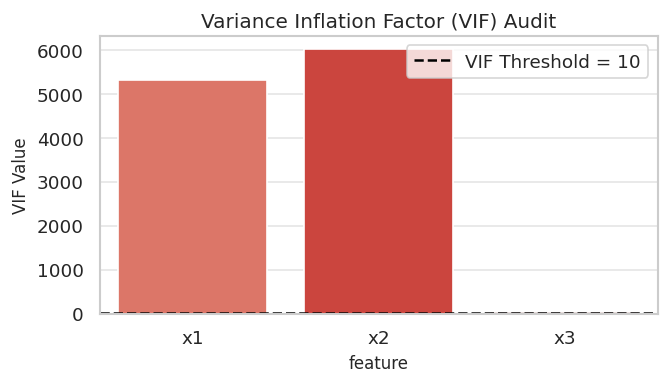

In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_vif = pd.DataFrame({
    'x1': [1, 2, 3, 4, 5],
    'x2': [2.1, 3.9, 6.2, 7.9, 10.1], # Perfectly collinear with x1
    'x3': [1, 0, 3, 2, 5]
})
print(X_vif)
print("_" * 60)

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print(vif_data)

# visualization
# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='feature', y='VIF', hue='feature', data=vif_data, palette='Reds_d', legend=False, errorbar=None)
plt.axhline(y=10, color='black', linestyle='--', label='VIF Threshold = 10')
plt.title('Variance Inflation Factor (VIF) Audit')
plt.ylabel('VIF Value')
plt.legend()
plt.show()

   Size_SqFt  Num_Bedrooms
0       1500             3
1       1600             3
2       1700             4
3       1800             4
4       1900             5
____________________________________________________________
        feature       VIF
0     Size_SqFt  9.333333
1  Num_Bedrooms  9.333333


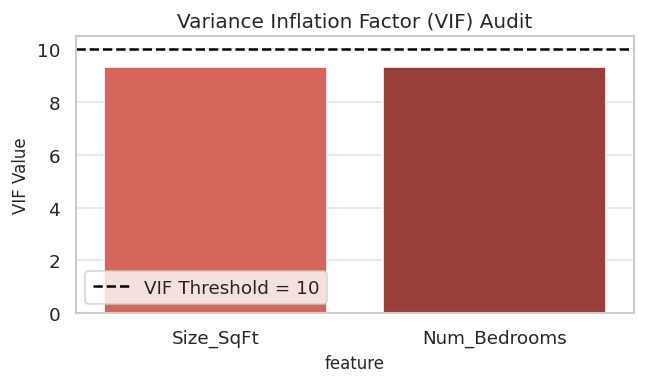

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_vif = pd.DataFrame({
    'Size_SqFt': [1500, 1600, 1700, 1800, 1900],
    'Num_Bedrooms': [3, 3, 4, 4, 5],
    # 'Size_SqMeters': [139.35, 148.64, 157.93, 167.22, 176.51]
})
print(X_vif)
print("_" * 60)

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print(vif_data)

# visualization
# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='feature', y='VIF', hue='feature', data=vif_data, palette='Reds_d', legend=False, errorbar=None)
plt.axhline(y=10, color='black', linestyle='--', label='VIF Threshold = 10')
plt.title('Variance Inflation Factor (VIF) Audit')
plt.ylabel('VIF Value')
plt.legend()
plt.show()

In [15]:
import pandas as pd
from scipy.stats import pearsonr, linregress

data1 = {
    'bowler': ["Anil", "Bhuvneshwar", "Jasprit", "Mohammed", "Rashid"],
    'overs': [10, 15, 20, 25, 30],
    'runs': [50, 100, 170, 80, 90],
    'wickets': [2, 3, 4, 5, 6]
}

df1 = pd.DataFrame(data1)

slope_r, intercept_r, _, _, _ = linregress(df1['overs'], df1['runs'])
predicted_runs = slope_r * df1['overs'] + intercept_r
residuals_runs = df1['runs'] - predicted_runs

slope_w, intercept_w, _, _, _ = linregress(df1['overs'], df1['wickets'])
predicted_wickets = slope_w * df1['overs'] + intercept_w
residuals_wickets = df1['wickets'] - predicted_wickets

partial_r, p_value = pearsonr(residuals_runs, residuals_wickets)
print(f"Partial Correlation between 'runs' and 'wickets' controlling for 'overs': {partial_r:.4f}, p-value: {p_value:.4f}")

Partial Correlation between 'runs' and 'wickets' controlling for 'overs': nan, p-value: nan


/tmp/ipykernel_9490/4177369773.py:21: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  partial_r, p_value = pearsonr(residuals_runs, residuals_wickets)
